# BMED318. Hands-on. Chapter 7. Frequency Filtering

## 1. Prepare input image.

### a) Read ‘skull.jpg’. Name the skull image array as im. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from numpy.fft import fft2, ifft2, fftshift
from scipy.ndimage import zoom

In [2]:
im = plt.imread('skull.jpg')

(452, 374)


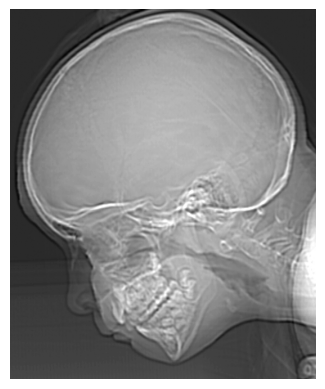

In [3]:
print(im.shape)

plt.imshow(im, cmap='gray')
plt.axis('off')
plt.show()

### b) Resize the im to 226x187. 

In [4]:
im = zoom(im, (226 / im.shape[0], 187 / im.shape[1]), order=1)

print(im.shape)

(226, 187)


## 2. Prepare a spatial domain filter

### a) Make 8x8 Gaussian filter with  = . . Name the filter array as lpf. 

In [5]:
# 2-a. Make 8x8 Gaussian filter

sigma = 1.0

x = np.arange(-3, 5)
y = np.arange(-3, 5)
X, Y = np.meshgrid(x, y)

lpf = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
lpf = lpf / np.sum(lpf)

print(lpf.shape)
print(np.max(lpf))

(8, 8)
0.15919850015996156


In [6]:
print(np.sum(lpf))
print(np.max(lpf))

1.0
0.15919850015996156


### b) Show the surface plot of lpf. The size of 8x8 filter mask is too small to make it look decent. Increase the number of samples (64x64 or 128x128, etc) before you plot the filter mask. (미려하게 보이기 위해서 이 단계에서만 이렇게 하면 됨. 실제 아래에서는 계속 8x8 필터마스크를 사용함)

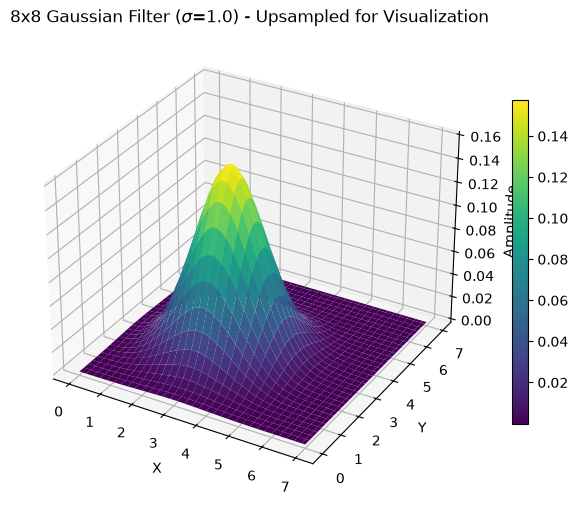

In [7]:
# 2-b. Upsample only for visualization

lpf_plot = zoom(lpf, 8, order=3)   # 8x8 -> 64x64

x_plot = np.linspace(0, 7, lpf_plot.shape[1])
y_plot = np.linspace(0, 7, lpf_plot.shape[0])
X_plot, Y_plot = np.meshgrid(x_plot, y_plot)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(
    X_plot, Y_plot, lpf_plot,
    cmap='viridis'
)

ax.set_title('8x8 Gaussian Filter ($\\sigma$=1.0) - Upsampled for Visualization')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Amplitude')

fig.colorbar(surf, ax=ax, shrink=0.7)

plt.show()

## 3. Get Fourier spectrums. 

### a) Zero-padding for the skull image: Make 256x256 zero matrix imz. Copy im to imz at the same pixel locations. 

In [8]:
# 3-a. Zero-padding for the skull image

imz = np.zeros((256, 256))

imz[:im.shape[0], :im.shape[1]] = im

print(imz.shape)

(256, 256)


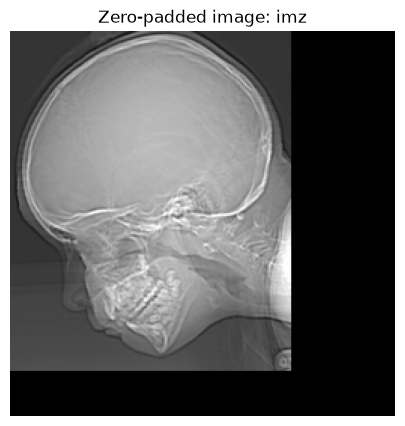

In [9]:
plt.figure(figsize=(5, 5))
plt.imshow(imz, cmap='gray')
plt.title('Zero-padded image: imz')
plt.axis('off')
plt.show()

### b) Zero-padding for the gaussian filter: Make 256x256 zero matrix lpfz. Copy the filter lpf to lpfz at the same pixel locations. 

In [10]:
# 3-b. Zero-padding for the Gaussian filter

lpfz = np.zeros((256, 256))

lpfz[:lpf.shape[0], :lpf.shape[1]] = lpf

print(lpfz.shape)

(256, 256)


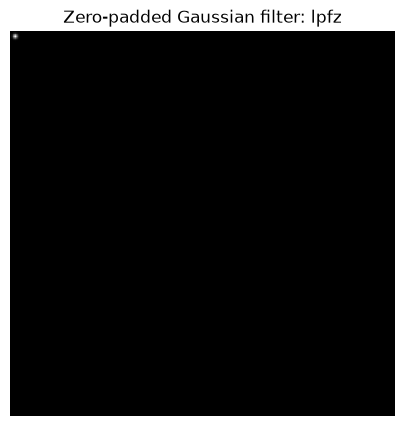

In [11]:
plt.figure(figsize=(5, 5))
plt.imshow(lpfz, cmap='gray')
plt.title('Zero-padded Gaussian filter: lpfz')
plt.axis('off')
plt.show()

### c) What is the most appropriate size of zero-padded array for this example? Explain the reason.

원본 영상의 크기는 226x187이고 Gaussian filter의 크기는 8x8 이므로, circular convolution을 방지하기 위해 필요한 최소 zero-padding 크기는
(226+8-1)x(187+8-1)=233x194
이다. frequency-domain filtering 시 선형 convolution 결과 크기 이상으로 zero-padding 해야 하며, FFT는 배열의 크기가 2^n일 때 효율적으로 계산된다. 따라서 233 x 194보다 크면서 각 변의 길이가 2^n인
256 x 256 이 본 예제에서 가장 적절한 zero-padded array의 크기이다

### d) Do Fourier transform imz and lpfz and store the results into IMZ and LPFZ respectively. 

In [12]:
# 3-d. Fourier transform

IMZ = fft2(imz)
LPFZ = fft2(lpfz)

print(IMZ.shape)
print(LPFZ.shape)

(256, 256)
(256, 256)


### e) The DC coefficients of IMZ and LPFZ are located at the index [0,0]. Circular-shift the arrays so that the DC coefficients should be located at center of the array. Name the resultant arrays as IMZ_CS and LPFZ_CS respectively. 

In [13]:
# 3-e. Circular shift so that DC is at the center

IMZ_CS = fftshift(IMZ)
LPFZ_CS = fftshift(LPFZ)

In [14]:
print(IMZ_CS.shape)
print(LPFZ_CS.shape)

(256, 256)
(256, 256)


### f) Display the magnitudes of IMZ, IMZ_CS, LPFZ, and LPFZ_CS as surface plots. 

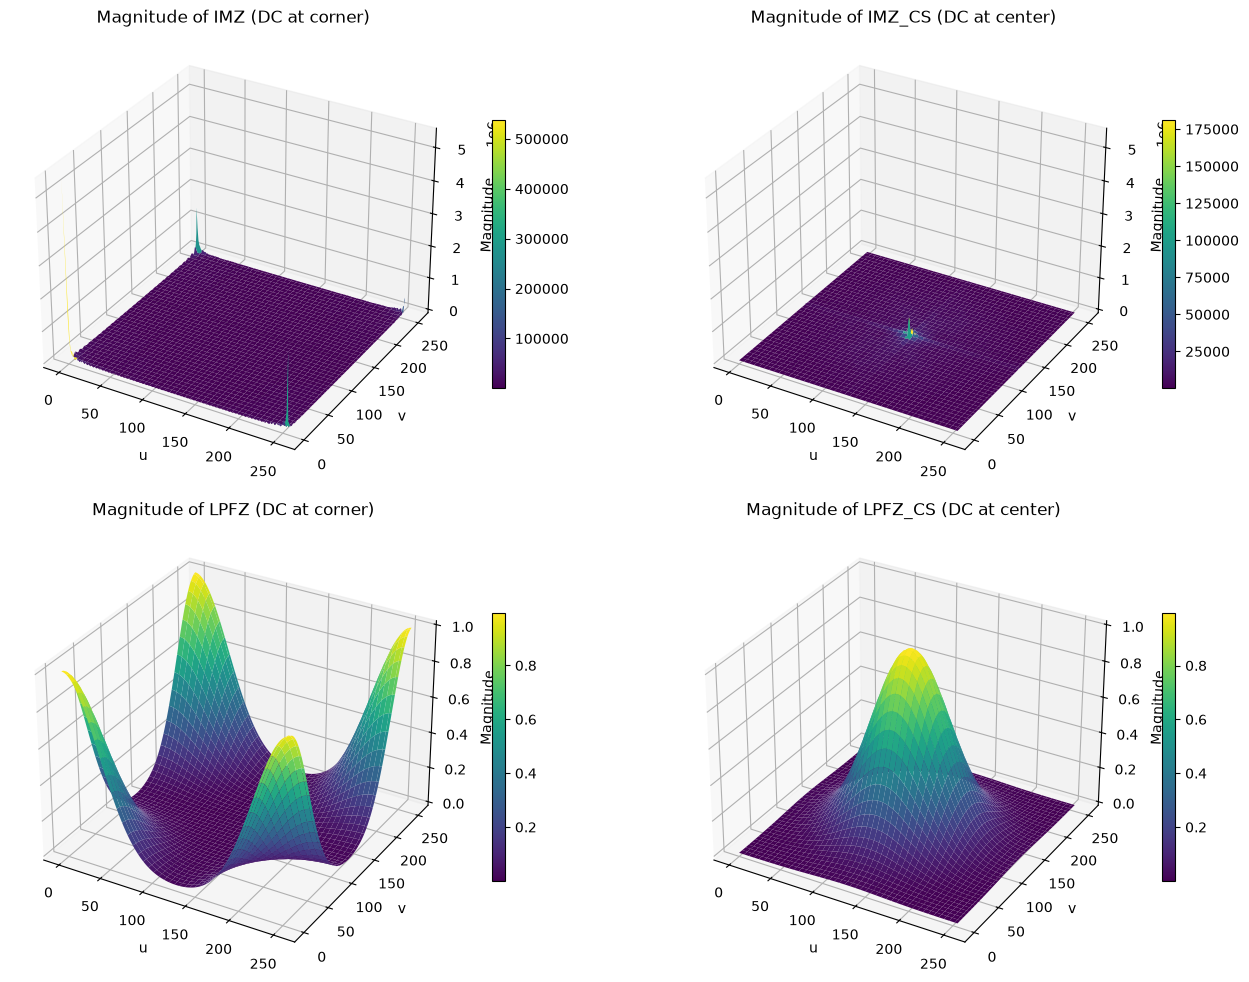

In [15]:
# 3-f. Display magnitudes as surface plots

x = np.arange(256)
y = np.arange(256)
X, Y = np.meshgrid(x, y)

fig = plt.figure(figsize=(14, 10))

# IMZ
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
s1 = ax1.plot_surface(X, Y, np.abs(IMZ), cmap='viridis')
ax1.set_title('Magnitude of IMZ (DC at corner)')
ax1.set_xlabel('u')
ax1.set_ylabel('v')
ax1.set_zlabel('Magnitude')
fig.colorbar(s1, ax=ax1, shrink=0.6)

# IMZ_CS
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
s2 = ax2.plot_surface(X, Y, np.abs(IMZ_CS), cmap='viridis')
ax2.set_title('Magnitude of IMZ_CS (DC at center)')
ax2.set_xlabel('u')
ax2.set_ylabel('v')
ax2.set_zlabel('Magnitude')
fig.colorbar(s2, ax=ax2, shrink=0.6)

# LPFZ
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
s3 = ax3.plot_surface(X, Y, np.abs(LPFZ), cmap='viridis')
ax3.set_title('Magnitude of LPFZ (DC at corner)')
ax3.set_xlabel('u')
ax3.set_ylabel('v')
ax3.set_zlabel('Magnitude')
fig.colorbar(s3, ax=ax3, shrink=0.6)

# LPFZ_CS
ax4 = fig.add_subplot(2, 2, 4, projection='3d')
s4 = ax4.plot_surface(X, Y, np.abs(LPFZ_CS), cmap='viridis')
ax4.set_title('Magnitude of LPFZ_CS (DC at center)')
ax4.set_xlabel('u')
ax4.set_ylabel('v')
ax4.set_zlabel('Magnitude')
fig.colorbar(s4, ax=ax4, shrink=0.6)

plt.tight_layout()
plt.show()

## 4. Frequency domain filtering: LPF

강의자료에서 설명한 바와 같이 위의 그림의 절차대로 im(그림에서  ), imz 와 lpfz를 이용하여
frequency filtering을 수행하시오. 중간결과들과 최종결과를 위의 그림 순서대로 나열하되 크기가 같은
그림끼리 모아서 보이시오. - 첫 figure:  와 , 둘째 figure:  부터 IDFT결과까지 보이면 됨. subplot()을 사용시 일부 그림이 깨
진 것처럼 보이면 figure window의 크기를 확대해주면 정상적으로 결과가 보임. subplot()을 사용하지
않을 경우 독립 figure로 만든 후 보고서에 위의 순서로 배열해서 보여주면 됨. - frequency spectrum 은 magnitude 만 보여주면 됨. - 그림의 , ,  등 frequency spectrum은 log scale로 보이시오. - IDFT후 복소수가 나오면 실수만 취하여 결과영상을 만드시오.

In [16]:
# 4. Frequency domain filtering: LPF

# f: original image
f = im

# fp: zero-padded image
fp = imz

P, Q = fp.shape

# (-1)^(x+y)
x, y = np.indices((P, Q))
checker = (-1) ** (x + y)

# Multiply fp by (-1)^(x+y)
fp_mod = fp * checker

# Fourier transform
Fp = fft2(fp_mod)

# H: centered frequency response of the Gaussian LPF
# LPFZ_CS was obtained in 3-e
H = LPFZ_CS

# Frequency-domain filtering
HFp = H * Fp

# IDFT -> take only real part
gp = np.real(ifft2(HFp))

# Multiply by (-1)^(x+y) again
gp = gp * checker

# Crop to original image size
g = gp[:f.shape[0], :f.shape[1]]

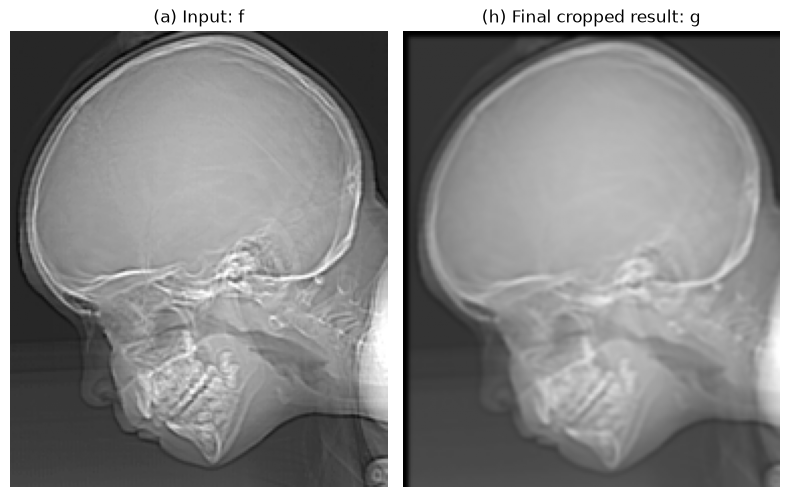

In [17]:
# Figure 1: f and g

fig, axes = plt.subplots(1, 2, figsize=(8, 5))

axes[0].imshow(f, cmap='gray')
axes[0].set_title('(a) Input: f')
axes[0].axis('off')

axes[1].imshow(g, cmap='gray')
axes[1].set_title('(h) Final cropped result: g')
axes[1].axis('off')

plt.tight_layout()
plt.show()

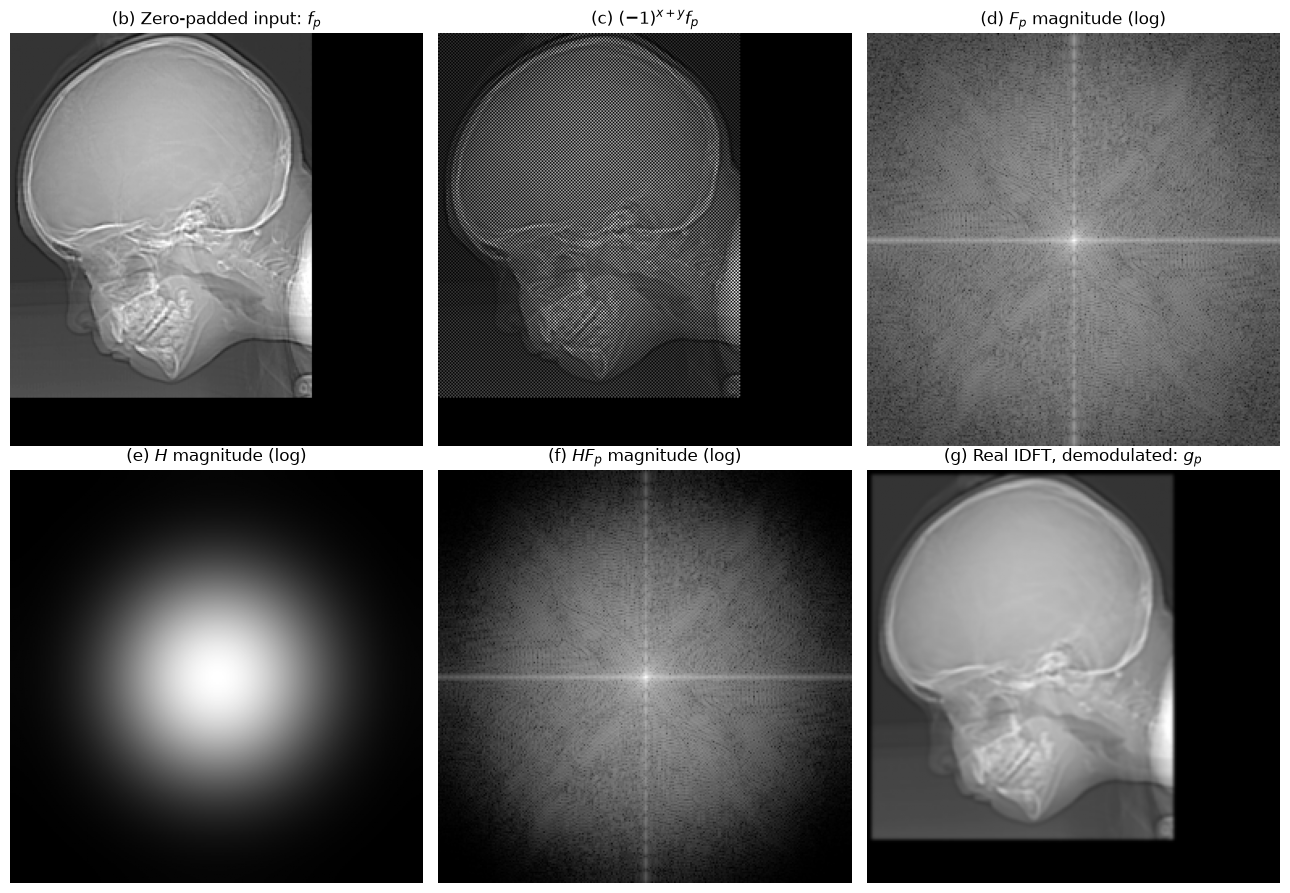

In [18]:
# Figure 2: fp through gp

fig, axes = plt.subplots(2, 3, figsize=(13, 9))

# fp
axes[0, 0].imshow(fp, cmap='gray')
axes[0, 0].set_title('(b) Zero-padded input: $f_p$')
axes[0, 0].axis('off')

# (-1)^(x+y) fp
axes[0, 1].imshow(
    fp_mod,
    cmap='gray',
    vmin=0,
    vmax=fp.max()
)
axes[0, 1].set_title('(c) $(-1)^{x+y}f_p$')
axes[0, 1].axis('off')

# Fp: magnitude, log scale
axes[0, 2].imshow(np.log1p(np.abs(Fp)), cmap='gray')
axes[0, 2].set_title('(d) $F_p$ magnitude (log)')
axes[0, 2].axis('off')

# H: magnitude, log scale
axes[1, 0].imshow(np.log1p(np.abs(H)), cmap='gray')
axes[1, 0].set_title('(e) $H$ magnitude (log)')
axes[1, 0].axis('off')

# HFp: magnitude, log scale
axes[1, 1].imshow(np.log1p(np.abs(HFp)), cmap='gray')
axes[1, 1].set_title('(f) $HF_p$ magnitude (log)')
axes[1, 1].axis('off')

# gp
axes[1, 2].imshow(gp, cmap='gray')
axes[1, 2].set_title('(g) Real IDFT, demodulated: $g_p$')
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

## 5. Frequency domain filtering: HPF

4번에서 수행한 frequency domain filtering을 수행하는 코드를 function으로 만든 후 아래 과정에 반복
사용하시오

In [19]:
def frequency_filter(im, H):
    # image size
    M, N = im.shape

    # 1. zero-padding to 256x256
    fp = np.zeros((256, 256))
    fp[:M, :N] = im

    # 2. multiply by (-1)^(x+y)
    x, y = np.indices((256, 256))
    checker = (-1) ** (x + y)

    fp_mod = fp * checker

    # 3. Fourier transform
    Fp = fft2(fp_mod)

    # 4. Apply frequency-domain filter
    HFp = H * Fp

    # 5. IDFT and take real part
    gp = np.real(ifft2(HFp))

    # 6. multiply by (-1)^(x+y) again
    gp = gp * checker

    # 7. crop back to original size
    g = gp[:M, :N]

    return g

### a) im에 대하여 ideal HPF를 적용하여 두개골과 얼굴의 외곽선 edge가 모두 선명하게 나오는 filter radius (cutoff frequency)를 제시하시오. 실험을 통하여 가장 적합한 값을 제시하고 입력영상과 함께 최종 결과영상을 보이시오.

실험

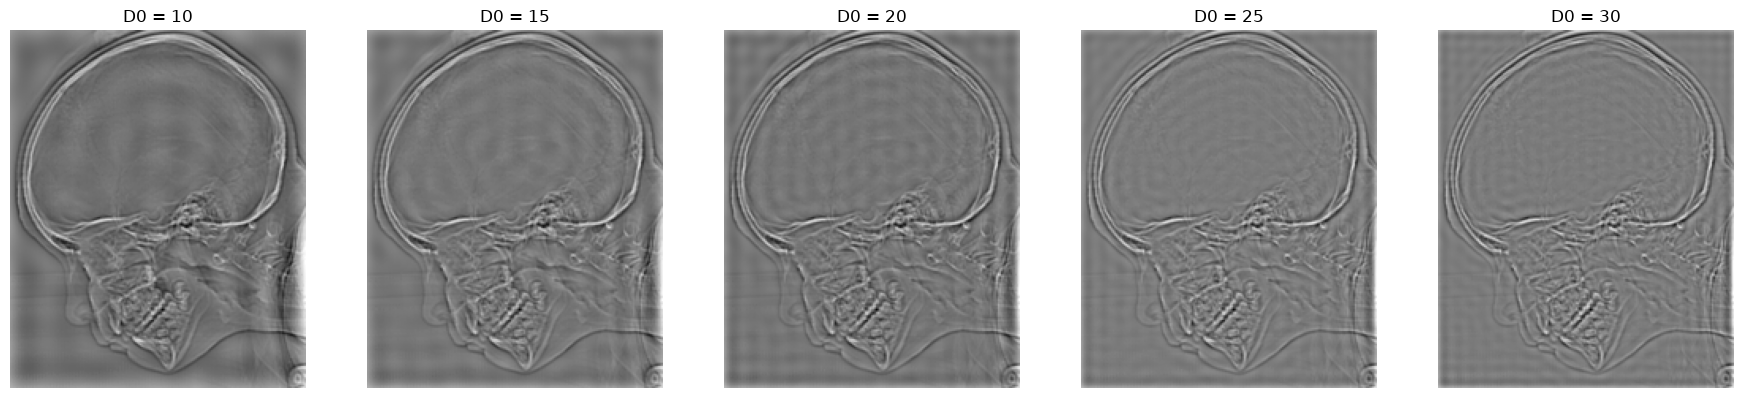

In [20]:
# 5-a. Ideal HPF - try several cutoff frequencies

P = Q = 256

u = np.arange(-Q//2, Q//2)
v = np.arange(-P//2, P//2)
U, V = np.meshgrid(u, v)

D = np.sqrt(U**2 + V**2)

cutoffs = [10, 15, 20, 25, 30]

fig, axes = plt.subplots(1, len(cutoffs), figsize=(18, 4))

for ax, D0 in zip(axes, cutoffs):

    # Ideal HPF
    H_ideal = (D > D0).astype(float)

    # 4번에서 만든 frequency filtering 함수 사용
    result = frequency_filter(im, H_ideal)

    ax.imshow(result, cmap='gray')
    ax.set_title(f'D0 = {D0}')
    ax.axis('off')

plt.tight_layout()
plt.show()

여러 cutoff frequency를 적용하여 결과를 비교한 결과, \(D_0=20\)에서 두개골과 얼굴의 외곽선이 모두 비교적 선명하게 나타났다. \(D_0\)가 너무 작은 경우 저주파 성분이 충분히 제거되지 않아 edge 강조 효과가 약하였고, 너무 큰 경우 영상의 주요 구조가 지나치게 제거되었다. 따라서 본 실험에서는 \(D_0=20\)을 가장 적절한 cutoff frequency로 선택하였다.

In [21]:
# Final Ideal HPF

D0 = 20

H_ideal = (D > D0).astype(float)

ideal_result = frequency_filter(im, H_ideal)

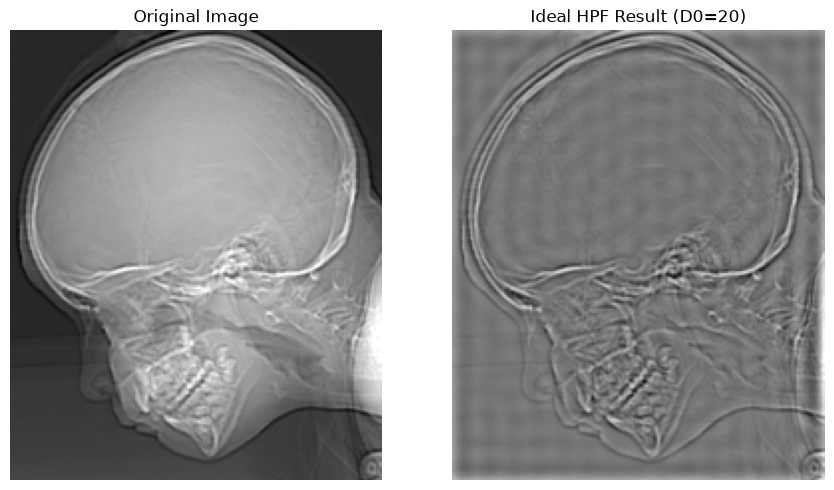

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(9, 5))

axes[0].imshow(im, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(ideal_result, cmap='gray')
axes[1].set_title(f'Ideal HPF Result (D0={D0})')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### b) im에 대하여 Gaussian HPF를 적용하고 두개골과 얼굴의 외곽선 edge가 모두 선명하게 나오는 standard deviation을 제시하시오. 실험을 통하여 가장 적합한 값을 제시하고 입력영상과 함께 최종 결과영상들을 보이시오.

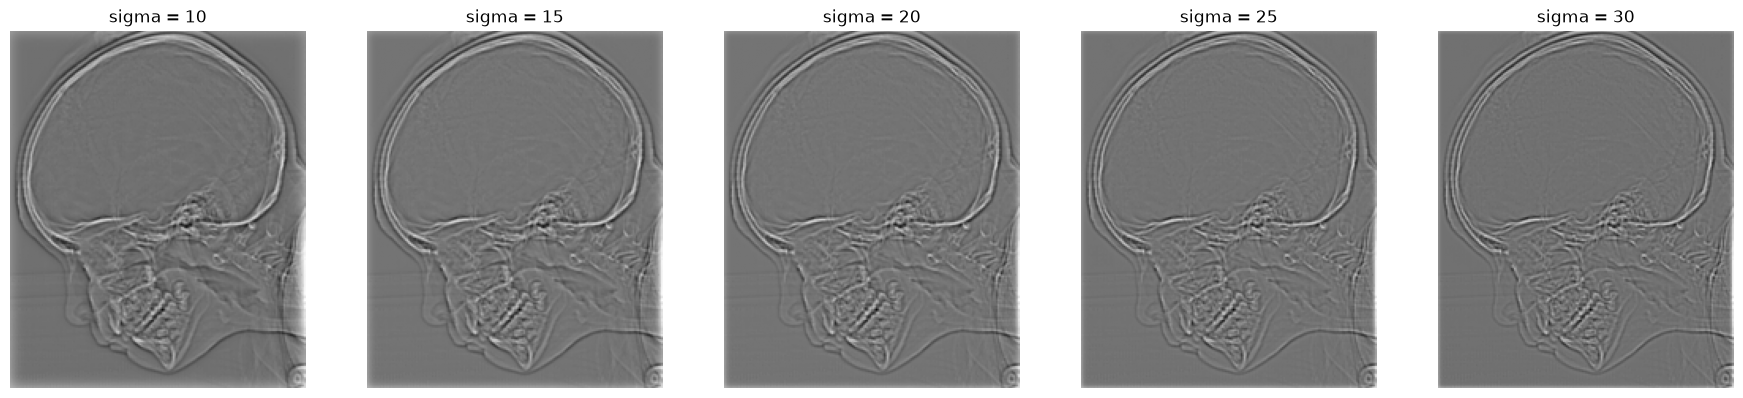

In [23]:
# 5-b. Gaussian HPF - try several standard deviations

sigmas = [10, 15, 20, 25, 30]

fig, axes = plt.subplots(1, len(sigmas), figsize=(18, 4))

for ax, sigma in zip(axes, sigmas):

    # Gaussian HPF
    H_gaussian = 1 - np.exp(-(D**2) / (2 * sigma**2))

    # frequency-domain filtering
    result = frequency_filter(im, H_gaussian)

    ax.imshow(result, cmap='gray')
    ax.set_title(f'sigma = {sigma}')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [24]:
# Final Gaussian HPF

sigma = 25

H_gaussian = 1 - np.exp(
    -(D**2) / (2 * sigma**2)
)

gaussian_result = frequency_filter(im, H_gaussian)

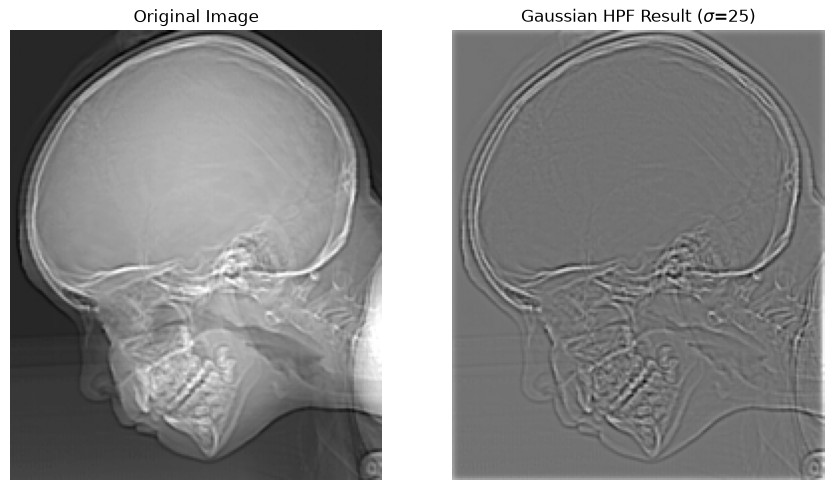

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(9, 5))

axes[0].imshow(im, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(gaussian_result, cmap='gray')
axes[1].set_title(f'Gaussian HPF Result ($\\sigma$={sigma})')
axes[1].axis('off')

plt.tight_layout()
plt.show()

여러 standard deviation을 적용하여 결과를 비교한 결과, sigma=25에서 두개골과 얼굴의 외곽선이 모두 비교적 선명하게 나타났다. sigma가 너무 작은 경우 저주파 성분의 제거가 충분하지 않아 edge 강조가 약했고, 너무 큰 경우 영상의 주요 구조가 지나치게 제거되었다. 따라서 본 실험에서는 sigma=25를 가장 적절한 값으로 선택하였다.Gaussian HPF는 주파수 응답이 부드럽게 변화하므로 Ideal HPF에 비해 ringing artifact가 적으면서 주요 경계 성분을 효과적으로 강조하였다.